# BCG X | PowerCo Customer Churn — Exploratory Data Analysis

**Task:** Understand the client datasets and investigate whether pricing may be associated with customer churn.

**Purpose of this notebook:** Complete the EDA stage requested in the Forage simulation: inspect column data types, understand distributions, create clear visualizations, and document initial observations.

> **Important:** This notebook explores associations; it does not prove that price changes cause churn. We will not build a predictive model in this EDA notebook.

## How to run
1. Keep this notebook in the same folder as `client_data.csv` and `price_data.csv`.
2. Install the required packages if needed: `pandas`, `numpy`, `matplotlib`, and `seaborn`.
3. Run the notebook from top to bottom.
4. Review the printed summaries and charts. Add your own interpretation in the reflection cells.

The notebook uses the two CSV files provided by the simulation. Column meanings are based on the provided **Data Description** PDF.

## 1. Import libraries and set display options

We use:
- **Pandas / NumPy** for data inspection and calculations.
- **Matplotlib / Seaborn** for visualizations.

In [4]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the provided datasets

The client dataset contains customer-level information, including consumption, contract details, forecast prices, margins, and the `churn` target. The price dataset contains historical prices by customer and reference date.

If your filenames differ, update the two paths below.

In [5]:
CLIENT_FILE = Path(r"C:\Users\riaka\Downloads\client_data (1).csv")
PRICE_FILE = Path(r"C:\Users\riaka\Downloads\price_data (1).csv")

if not CLIENT_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {CLIENT_FILE.resolve()}. "
        "Place client_data.csv in the same folder as this notebook, "
        "or update CLIENT_FILE to the correct path."
    )
if not PRICE_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {PRICE_FILE.resolve()}. "
        "Place price_data.csv in the same folder as this notebook, "
        "or update PRICE_FILE to the correct path."
    )

client_df = pd.read_csv(CLIENT_FILE)
price_df = pd.read_csv(PRICE_FILE)

print(f"Client dataset: {client_df.shape[0]:,} rows × {client_df.shape[1]} columns")
print(f"Price dataset:  {price_df.shape[0]:,} rows × {price_df.shape[1]} columns")

display(client_df.head())
display(price_df.head())

Client dataset: 14,606 rows × 26 columns
Price dataset:  193,002 rows × 8 columns


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.000,0,0.000,1.780,0.114,0.098,40.607,t,0.000,25.440,25.440,2,678.990,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.950,0,0.000,16.270,0.146,0.000,44.311,f,0.000,16.380,16.380,1,18.890,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.960,0,0.000,38.720,0.166,0.088,44.311,f,0.000,28.600,28.600,1,6.600,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.040,0,0.000,19.830,0.147,0.000,44.311,f,0.000,30.220,30.220,1,25.460,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.750,526,0.000,131.730,0.117,0.100,40.607,f,52.320,44.910,44.910,1,47.980,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151,0.000,0.000,44.267,0.000,0.000
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151,0.000,0.000,44.267,0.000,0.000
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151,0.000,0.000,44.267,0.000,0.000
3,038af19179925da21a25619c5a24b745,2015-04-01,0.150,0.000,0.000,44.267,0.000,0.000
4,038af19179925da21a25619c5a24b745,2015-05-01,0.150,0.000,0.000,44.267,0.000,0.000


## 3. Understand the columns and data types

First inspect the schema. Date columns may be stored as text in the original CSV; we will convert them after reviewing the raw data.

In [6]:
print("CLIENT DATA INFO")
client_df.info()

print("\nPRICE DATA INFO")
price_df.info()

print("\nClient column names:")
print(client_df.columns.tolist())

print("\nPrice column names:")
print(price_df.columns.tolist())

CLIENT DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_

### Data dictionary — client dataset

The supplied description identifies `id` as the client company identifier and `churn` as whether the client churned over the following three months. Some text fields are hashed; their commercial meaning is retained, but their codes may not be human-readable.

In [7]:
client_dictionary = pd.DataFrame([
    ("id", "Customer/company identifier"),
    ("activity_new", "Category of the company's activity"),
    ("channel_sales", "Code of the sales channel"),
    ("cons_12m", "Electricity consumption over the past 12 months"),
    ("cons_gas_12m", "Gas consumption over the past 12 months"),
    ("cons_last_month", "Electricity consumption in the last month"),
    ("date_activ", "Contract activation date"),
    ("date_end", "Registered contract end date"),
    ("date_modif_prod", "Date of last product modification"),
    ("date_renewal", "Next contract renewal date"),
    ("forecast_cons_12m", "Forecast electricity consumption for next 12 months"),
    ("forecast_cons_year", "Forecast electricity consumption for next calendar year"),
    ("forecast_discount_energy", "Forecast value of current energy discount"),
    ("forecast_meter_rent_12m", "Forecast meter-rental bill field; confirm period in source documentation"),
    ("forecast_price_energy_off_peak", "Forecast off-peak energy price"),
    ("forecast_price_energy_peak", "Forecast peak energy price"),
    ("forecast_price_pow_off_peak", "Forecast off-peak power price"),
    ("has_gas", "Whether the client also uses gas"),
    ("imp_cons", "Current paid consumption"),
    ("margin_gross_pow_ele", "Gross margin on power subscription"),
    ("margin_net_pow_ele", "Net margin on power subscription"),
    ("nb_prod_act", "Number of active products/services"),
    ("net_margin", "Total net margin"),
    ("num_years_antig", "Client tenure in years"),
    ("origin_up", "Code of the campaign through which the customer first subscribed"),
    ("pow_max", "Subscribed power"),
    ("churn", "Whether the client churned over the next three months"),
], columns=["column", "meaning"])

display(client_dictionary)

,column,meaning
0,id,Customer/company identifier
1,activity_new,Category of the company's activity
2,channel_sales,Code of the sales channel
3,cons_12m,Electricity consumption over the past 12 months
4,cons_gas_12m,Gas consumption over the past 12 months
5,cons_last_month,Electricity consumption in the last month
6,date_activ,Contract activation date
7,date_end,Registered contract end date
8,date_modif_prod,Date of last product modification
9,date_renewal,Next contract renewal date


### Data dictionary — price dataset

Each row represents a customer's prices at a reference date. Repeated customer IDs are expected here because pricing is recorded over time.

In [8]:
price_dictionary = pd.DataFrame([
    ("id", "Customer/company identifier"),
    ("price_date", "Reference date for the price record"),
    ("price_off_peak_var", "Off-peak variable energy price"),
    ("price_peak_var", "Peak variable energy price"),
    ("price_mid_peak_var", "Mid-peak variable energy price"),
    ("price_off_peak_fix", "Off-peak fixed power price"),
    ("price_peak_fix", "Peak fixed power price"),
    ("price_mid_peak_fix", "Mid-peak fixed power price"),
], columns=["column", "meaning"])

display(price_dictionary)

,column,meaning
0,id,Customer/company identifier
1,price_date,Reference date for the price record
2,price_off_peak_var,Off-peak variable energy price
3,price_peak_var,Peak variable energy price
4,price_mid_peak_var,Mid-peak variable energy price
5,price_off_peak_fix,Off-peak fixed power price
6,price_peak_fix,Peak fixed power price
7,price_mid_peak_fix,Mid-peak fixed power price


## 4. Data quality checks

We check missing values, exact duplicate rows, unique customer IDs, and the validity of the churn target. A dataset can have no missing values and still contain unusual values or data-quality issues.

In [9]:
quality_summary = pd.DataFrame({
    "client_missing": client_df.isna().sum(),
    "client_dtype": client_df.dtypes.astype(str),
})
display(quality_summary)

price_quality = pd.DataFrame({
    "price_missing": price_df.isna().sum(),
    "price_dtype": price_df.dtypes.astype(str),
})
display(price_quality)

print("Exact duplicate rows — client:", client_df.duplicated().sum())
print("Exact duplicate rows — price:", price_df.duplicated().sum())
print("Unique client IDs:", client_df["id"].nunique() if "id" in client_df else "id column not found")
print("Unique IDs in price data:", price_df["id"].nunique() if "id" in price_df else "id column not found")

if "churn" in client_df.columns:
    print("\nValues found in churn:", sorted(client_df["churn"].dropna().unique().tolist()))

,client_missing,client_dtype
id,0,object
channel_sales,0,object
cons_12m,0,int64
cons_gas_12m,0,int64
cons_last_month,0,int64
date_activ,0,object
date_end,0,object
date_modif_prod,0,object
date_renewal,0,object
forecast_cons_12m,0,float64


,price_missing,price_dtype
id,0,object
price_date,0,object
price_off_peak_var,0,float64
price_peak_var,0,float64
price_mid_peak_var,0,float64
price_off_peak_fix,0,float64
price_peak_fix,0,float64
price_mid_peak_fix,0,float64


Exact duplicate rows — client: 0
Exact duplicate rows — price: 0
Unique client IDs: 14606
Unique IDs in price data: 16096

Values found in churn: [0, 1]


### Interpretation checkpoint

Write down:
- Are there missing values?
- Are there exact duplicate rows?
- Are date columns stored in the correct type?
- Does `churn` contain only the expected binary values?

Do not delete rows or fill values without a reason. Repeated IDs in the price dataset are not duplicates by themselves.

## 5. Convert date fields and check date coverage

The four client date fields are converted to datetime. Invalid values, if any, become `NaT` and are counted below. We also inspect the historical pricing date range.

In [10]:
client_date_cols = [
    col for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]
    if col in client_df.columns
]
for col in client_date_cols:
    client_df[col] = pd.to_datetime(client_df[col], errors="coerce")

if "price_date" in price_df.columns:
    price_df["price_date"] = pd.to_datetime(price_df["price_date"], errors="coerce")

print("Missing/invalid values after date conversion — client:")
display(client_df[client_date_cols].isna().sum().to_frame("missing_or_invalid_dates"))

if "price_date" in price_df.columns:
    print("Price date range:", price_df["price_date"].min(), "to", price_df["price_date"].max())
    print("Invalid price dates:", price_df["price_date"].isna().sum())

Missing/invalid values after date conversion — client:


,missing_or_invalid_dates
date_activ,0
date_end,0
date_modif_prod,0
date_renewal,0


Price date range: 2015-01-01 00:00:00 to 2015-12-01 00:00:00
Invalid price dates: 0


## 6. Descriptive statistics

`describe()` summarizes numerical columns. The median (50%) can be compared with the mean to identify potential skew. Large maxima should be investigated, not automatically removed.

In [11]:
print("CLIENT NUMERICAL SUMMARY")
display(client_df.describe(include=[np.number]).T)

print("PRICE NUMERICAL SUMMARY")
display(price_df.describe(include=[np.number]).T)

print("CLIENT CATEGORICAL SUMMARY")
display(client_df.describe(include=["object", "category"]).T)

CLIENT NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
cons_12m,"14,606.000","159,220.286","573,465.264",0.000,"5,674.750","14,115.500","40,763.750","6,207,104.000"
cons_gas_12m,"14,606.000","28,092.375","162,973.059",0.000,0.000,0.000,0.000,"4,154,590.000"
cons_last_month,"14,606.000","16,090.270","64,364.196",0.000,0.000,792.500,"3,383.000","771,203.000"
forecast_cons_12m,"14,606.000","1,868.615","2,387.572",0.000,494.995,"1,112.875","2,401.790","82,902.830"
forecast_cons_year,"14,606.000","1,399.763","3,247.786",0.000,0.000,314.000,"1,745.750","175,375.000"
forecast_discount_energy,"14,606.000",0.967,5.108,0.000,0.000,0.000,0.000,30.000
forecast_meter_rent_12m,"14,606.000",63.087,66.166,0.000,16.180,18.795,131.030,599.310
forecast_price_energy_off_peak,"14,606.000",0.137,0.025,0.000,0.116,0.143,0.146,0.274
forecast_price_energy_peak,"14,606.000",0.050,0.049,0.000,0.000,0.084,0.099,0.196
forecast_price_pow_off_peak,"14,606.000",43.130,4.486,0.000,40.607,44.311,44.311,59.266


PRICE NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
price_off_peak_var,"193,002.000",0.141,0.025,0.000,0.126,0.146,0.152,0.281
price_peak_var,"193,002.000",0.055,0.050,0.000,0.000,0.085,0.102,0.230
price_mid_peak_var,"193,002.000",0.030,0.036,0.000,0.000,0.000,0.073,0.114
price_off_peak_fix,"193,002.000",43.334,5.410,0.000,40.729,44.267,44.445,59.445
price_peak_fix,"193,002.000",10.623,12.842,0.000,0.000,0.000,24.340,36.491
price_mid_peak_fix,"193,002.000",6.410,7.774,0.000,0.000,0.000,16.226,17.458


CLIENT CATEGORICAL SUMMARY


,count,unique,top,freq
id,14606,14606,24011ae4ebbe3035111d65fa7c15bc57,1
channel_sales,14606,8,foosdfpfkusacimwkcsosbicdxkicaua,6754
has_gas,14606,2,f,11955
origin_up,14606,6,lxidpiddsbxsbosboudacockeimpuepw,7097


## 7. Churn distribution

The target is `churn`: 1 indicates a customer churned and 0 indicates they did not. We report both counts and percentages because churn may be a minority class.

,customers,percentage
churn,,
0,13187,90.280
1,1419,9.720


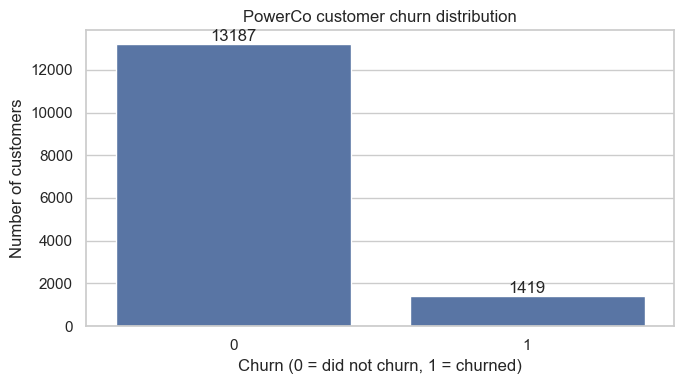

In [12]:
if "churn" not in client_df.columns:
    raise KeyError("Expected target column 'churn' was not found.")

churn_counts = client_df["churn"].value_counts(dropna=False).sort_index()
churn_pct = (client_df["churn"].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2)

churn_summary = pd.DataFrame({"customers": churn_counts, "percentage": churn_pct})
display(churn_summary)

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=client_df, x="churn", order=sorted(client_df["churn"].dropna().unique()))
ax.set_title("PowerCo customer churn distribution")
ax.set_xlabel("Churn (0 = did not churn, 1 = churned)")
ax.set_ylabel("Number of customers")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

## 8. Numerical distributions and potential outliers

These plots show the shape of selected consumption and forecast variables. The data may be right-skewed, so the median and upper quantiles are often informative. Do not remove high values solely because they look unusual.

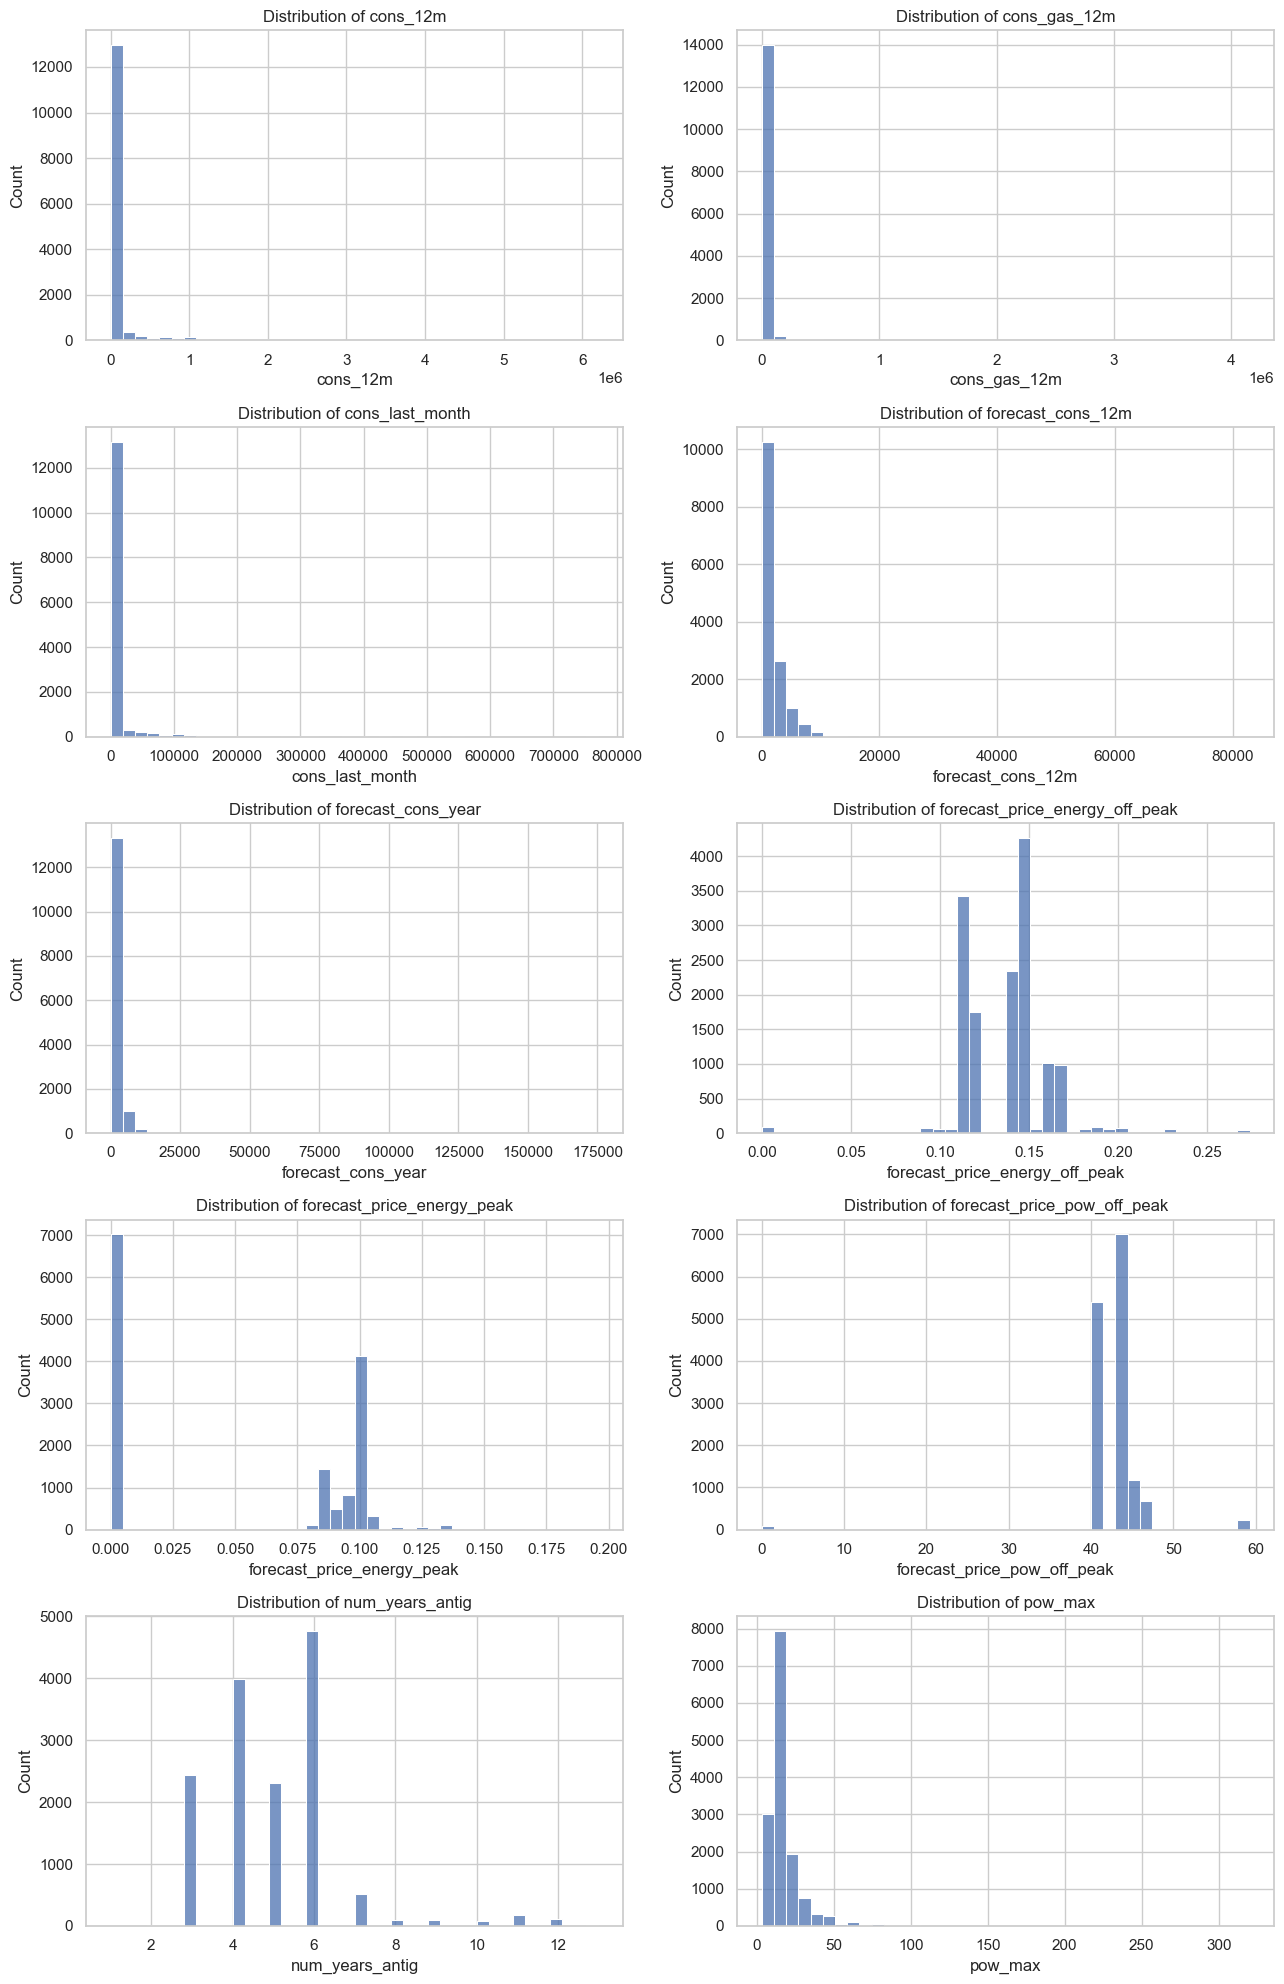

In [13]:
distribution_cols = [
    col for col in [
        "cons_12m", "cons_gas_12m", "cons_last_month",
        "forecast_cons_12m", "forecast_cons_year",
        "forecast_price_energy_off_peak", "forecast_price_energy_peak",
        "forecast_price_pow_off_peak", "num_years_antig", "pow_max"
    ] if col in client_df.columns
]

ncols = 2
nrows = int(np.ceil(len(distribution_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
axes = np.array(axes).reshape(-1)

for col, ax in zip(distribution_cols, axes):
    sns.histplot(data=client_df, x=col, bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)

for ax in axes[len(distribution_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Optional: log-scale view for heavily skewed variables

A log-scale view can make the bulk of a right-skewed distribution easier to see. This plot uses `log1p`, which handles zero values. It does not modify the underlying dataset.

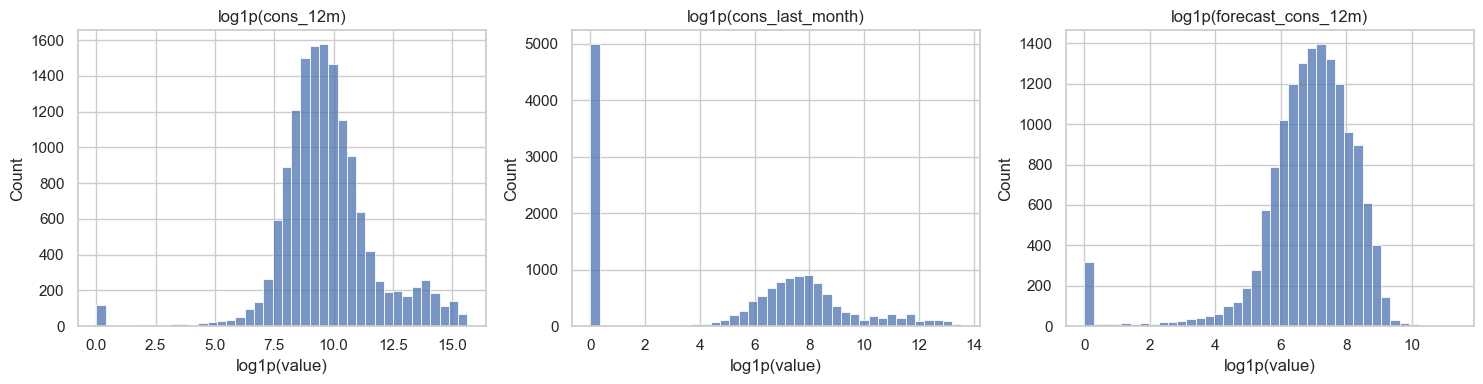

In [14]:
skew_cols = [c for c in ["cons_12m", "cons_last_month", "forecast_cons_12m"] if c in client_df.columns]
fig, axes = plt.subplots(1, len(skew_cols), figsize=(5 * len(skew_cols), 4))
if len(skew_cols) == 1:
    axes = [axes]

for col, ax in zip(skew_cols, axes):
    values = pd.to_numeric(client_df[col], errors="coerce").dropna()
    sns.histplot(np.log1p(values.clip(lower=0)), bins=40, ax=ax)
    ax.set_title(f"log1p({col})")
    ax.set_xlabel("log1p(value)")

plt.tight_layout()
plt.show()

## 9. Categorical variables

Hashed text fields may contain many distinct codes. We inspect the number of unique values and show the most common categories for selected columns. We do not assume the hashed codes have a natural order.

In [15]:
categorical_cols = [
    col for col in ["channel_sales", "activity_new", "has_gas", "origin_up"]
    if col in client_df.columns
]

cat_summary = pd.DataFrame({
    "unique_values": client_df[categorical_cols].nunique(dropna=False),
    "missing_values": client_df[categorical_cols].isna().sum(),
})
display(cat_summary)

for col in categorical_cols:
    print(f"\nTop values for {col}:")
    display(client_df[col].value_counts(dropna=False).head(10).to_frame("count"))

,unique_values,missing_values
channel_sales,8,0
has_gas,2,0
origin_up,6,0



Top values for channel_sales:


,count
channel_sales,
foosdfpfkusacimwkcsosbicdxkicaua,6754
MISSING,3725
lmkebamcaaclubfxadlmueccxoimlema,1843
usilxuppasemubllopkaafesmlibmsdf,1375
ewpakwlliwisiwduibdlfmalxowmwpci,893
sddiedcslfslkckwlfkdpoeeailfpeds,11
epumfxlbckeskwekxbiuasklxalciiuu,3
fixdbufsefwooaasfcxdxadsiekoceaa,2



Top values for has_gas:


,count
has_gas,
f,11955
t,2651



Top values for origin_up:


,count
origin_up,
lxidpiddsbxsbosboudacockeimpuepw,7097
kamkkxfxxuwbdslkwifmmcsiusiuosws,4294
ldkssxwpmemidmecebumciepifcamkci,3148
MISSING,64
usapbepcfoloekilkwsdiboslwaxobdp,2
ewxeelcelemmiwuafmddpobolfuxioce,1


## 10. Churn rate by selected customer characteristics

We compare churn rates across a few categories. These are descriptive associations, not proof of causation. Very small groups may produce unstable percentages, so group sizes are shown alongside churn rates.


Churn summary by has_gas (top 15 groups by customer count):


,customers,churn_rate,churn_rate_pct
has_gas,,,
f,11955,0.101,10.050
t,2651,0.082,8.190


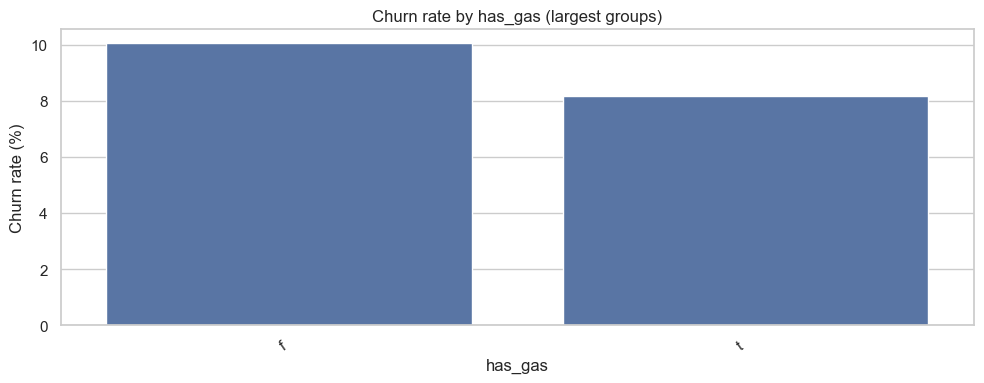


Churn summary by channel_sales (top 15 groups by customer count):


,customers,churn_rate,churn_rate_pct
channel_sales,,,
foosdfpfkusacimwkcsosbicdxkicaua,6754,0.121,12.140
MISSING,3725,0.076,7.600
lmkebamcaaclubfxadlmueccxoimlema,1843,0.056,5.590
usilxuppasemubllopkaafesmlibmsdf,1375,0.100,10.040
ewpakwlliwisiwduibdlfmalxowmwpci,893,0.084,8.400
sddiedcslfslkckwlfkdpoeeailfpeds,11,0.000,0.000
epumfxlbckeskwekxbiuasklxalciiuu,3,0.000,0.000
fixdbufsefwooaasfcxdxadsiekoceaa,2,0.000,0.000


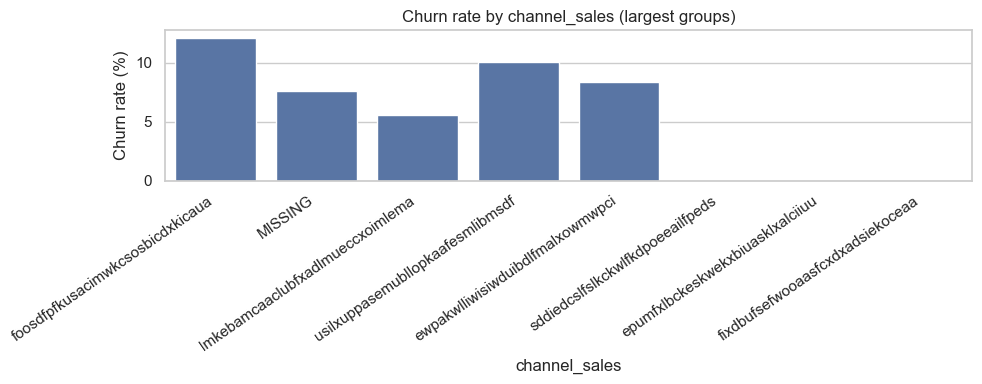


Churn summary by origin_up (top 15 groups by customer count):


,customers,churn_rate,churn_rate_pct
origin_up,,,
lxidpiddsbxsbosboudacockeimpuepw,7097,0.126,12.580
kamkkxfxxuwbdslkwifmmcsiusiuosws,4294,0.060,6.010
ldkssxwpmemidmecebumciepifcamkci,3148,0.084,8.390
MISSING,64,0.062,6.250
usapbepcfoloekilkwsdiboslwaxobdp,2,0.000,0.000
ewxeelcelemmiwuafmddpobolfuxioce,1,0.000,0.000


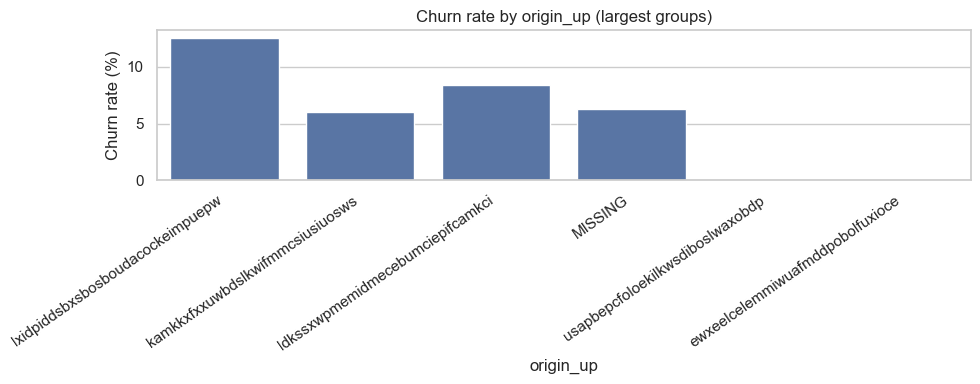

In [16]:
categorical_for_churn = [c for c in ["has_gas", "channel_sales", "activity_new", "origin_up"] if c in client_df.columns]

for col in categorical_for_churn:
    summary = (
        client_df.groupby(col, dropna=False)
        .agg(customers=("churn", "size"), churn_rate=("churn", "mean"))
        .assign(churn_rate_pct=lambda x: (x["churn_rate"] * 100).round(2))
        .sort_values("customers", ascending=False)
    )
    print(f"\nChurn summary by {col} (top 15 groups by customer count):")
    display(summary.head(15))

    plot_data = summary.head(10).reset_index()
    plt.figure(figsize=(10, 4))
    sns.barplot(data=plot_data, x=col, y="churn_rate_pct")
    plt.title(f"Churn rate by {col} (largest groups)")
    plt.xlabel(col)
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## 11. Price data: inspect trends and customer-level price variation

The price table contains multiple dated records per customer. First we summarize prices over time. Then we create simple per-customer price summaries and join them to the client table using `id`.

This is exploratory only. We must be cautious about timing: churn is defined over the next three months, so price features should eventually be constructed using information available before the prediction period to avoid leakage.

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
price_date,,,,,,
2015-01-01,0.143,0.055,0.030,43.227,10.693,6.456
2015-02-01,0.143,0.055,0.030,43.238,10.674,6.449
2015-03-01,0.143,0.055,0.030,43.254,10.644,6.430
2015-04-01,0.143,0.056,0.030,43.288,10.647,6.423
2015-05-01,0.144,0.055,0.030,43.315,10.602,6.391


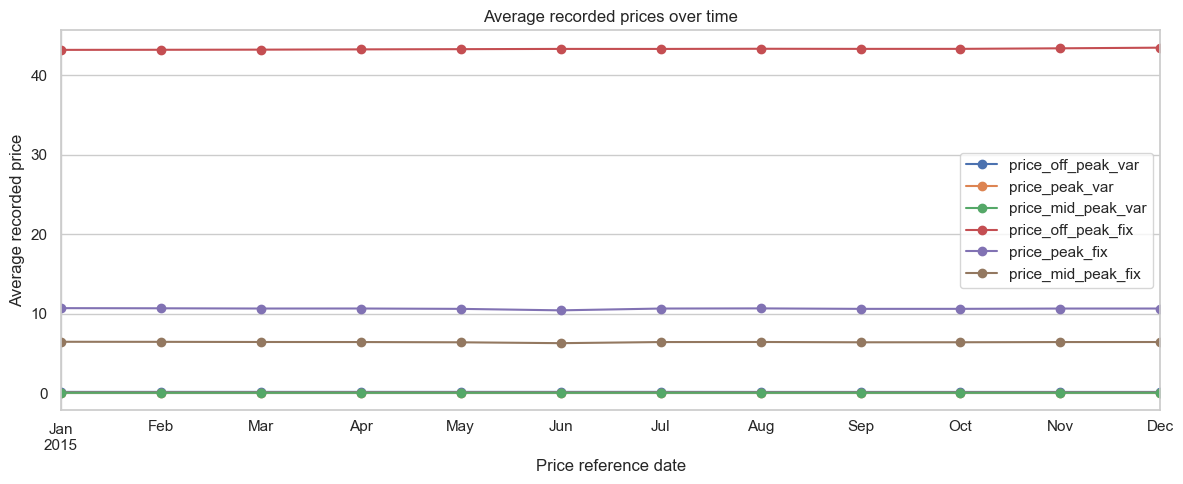

In [17]:
price_cols = [
    c for c in [
        "price_off_peak_var", "price_peak_var", "price_mid_peak_var",
        "price_off_peak_fix", "price_peak_fix", "price_mid_peak_fix"
    ] if c in price_df.columns
]

if "price_date" in price_df.columns and price_cols:
    monthly_price = price_df.groupby("price_date")[price_cols].mean().sort_index()
    display(monthly_price.head())

    ax = monthly_price.plot(figsize=(12, 5), marker="o")
    ax.set_title("Average recorded prices over time")
    ax.set_xlabel("Price reference date")
    ax.set_ylabel("Average recorded price")
    plt.tight_layout()
    plt.show()
else:
    print("Price date or expected price columns are missing; review the dataset schema.")

In [18]:
# Summarize the average and variability of each customer's observed prices.
customer_price_summary = (
    price_df.groupby("id")[price_cols]
    .agg(["mean", "std", "min", "max"])
)

# Flatten multi-level column names for easier use.
customer_price_summary.columns = [
    f"{col}_{stat}" for col, stat in customer_price_summary.columns
]
customer_price_summary = customer_price_summary.reset_index()

print("Customer-level price summary shape:", customer_price_summary.shape)
display(customer_price_summary.head())

# Merge for exploratory comparisons; preserve one row per client.
eda_df = client_df.merge(
    customer_price_summary,
    on="id",
    how="left",
    validate="one_to_one"
)

print("Merged EDA dataset shape:", eda_df.shape)
print("Clients without matched price history:", eda_df.filter(regex="_mean$").isna().all(axis=1).sum())

Customer-level price summary shape: (16096, 25)


,id,price_off_peak_var_mean,price_off_peak_var_std,price_off_peak_var_min,price_off_peak_var_max,price_peak_var_mean,price_peak_var_std,price_peak_var_min,price_peak_var_max,price_mid_peak_var_mean,price_mid_peak_var_std,price_mid_peak_var_min,price_mid_peak_var_max,price_off_peak_fix_mean,price_off_peak_fix_std,price_off_peak_fix_min,price_off_peak_fix_max,price_peak_fix_mean,price_peak_fix_std,price_peak_fix_min,price_peak_fix_max,price_mid_peak_fix_mean,price_mid_peak_fix_std,price_mid_peak_fix_min,price_mid_peak_fix_max
0,0002203ffbb812588b632b9e628cc38d,0.124,0.004,0.120,0.128,0.104,0.002,0.102,0.106,0.073,0.001,0.070,0.074,40.702,0.063,40.566,40.729,24.421,0.038,24.340,24.437,16.281,0.025,16.226,16.292
1,0004351ebdd665e6ee664792efc4fd13,0.146,0.002,0.144,0.148,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,44.385,0.088,44.267,44.445,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.182,0.026,0.151,0.206,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,45.320,0.772,44.445,45.945,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0010ee3855fdea87602a5b7aba8e42de,0.119,0.005,0.113,0.123,0.098,0.003,0.095,0.101,0.069,0.000,0.069,0.069,40.647,0.085,40.566,40.729,24.388,0.051,24.340,24.437,16.259,0.034,16.226,16.292
4,00114d74e963e47177db89bc70108537,0.148,0.002,0.145,0.150,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,44.267,0.000,44.267,44.267,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Merged EDA dataset shape: (14606, 50)
Clients without matched price history: 0


## 12. Compare price summaries between churn groups

We compare mean customer-level prices by churn status. Differences may help prioritize further analysis, but they do not establish that pricing caused churn. The price data must also be aligned to a valid pre-churn time window for causal or predictive conclusions.

churn,0,1
price_off_peak_var_mean,0.142,0.142
price_peak_var_mean,0.052,0.057
price_mid_peak_var_mean,0.028,0.033
price_off_peak_fix_mean,42.904,43.162
price_peak_fix_mean,9.274,11.197
price_mid_peak_fix_mean,5.983,7.160


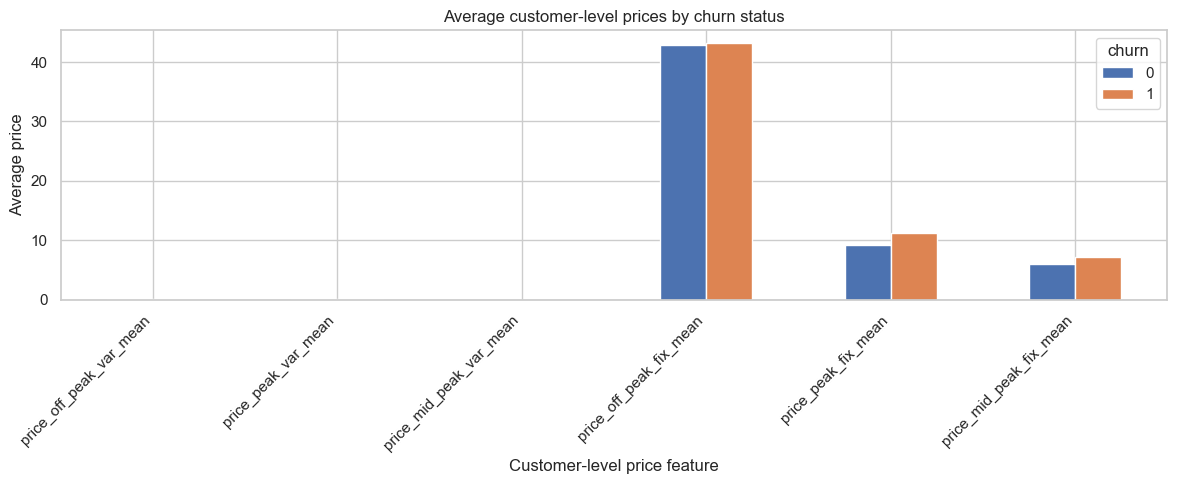

In [19]:
mean_price_features = [
    c for c in eda_df.columns
    if c.endswith("_mean") and any(term in c for term in ["price_off_peak", "price_peak", "price_mid_peak"])
]

if mean_price_features:
    price_by_churn = eda_df.groupby("churn")[mean_price_features].mean().T
    display(price_by_churn)

    price_by_churn.plot(kind="bar", figsize=(12, 5))
    plt.title("Average customer-level prices by churn status")
    plt.xlabel("Customer-level price feature")
    plt.ylabel("Average price")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No expected customer-level price mean features were found.")

## 13. Numeric variables by churn status

Compare descriptive statistics for selected numerical features across churn groups. Differences are useful for hypothesis generation but may be affected by confounding and extreme values.

In [20]:
numeric_compare_cols = [
    c for c in [
        "cons_12m", "cons_gas_12m", "cons_last_month",
        "forecast_cons_12m", "forecast_price_energy_off_peak",
        "forecast_price_energy_peak", "margin_net_pow_ele",
        "net_margin", "num_years_antig", "pow_max"
    ] if c in client_df.columns
]

display(
    client_df.groupby("churn")[numeric_compare_cols]
    .agg(["count", "mean", "median"])
    .T
)

churn                                           0          1
cons_12m                       count   13,187.000  1,419.000
                               mean   167,867.267 78,862.479
                               median  14,075.000 14,529.000
cons_gas_12m                   count   13,187.000  1,419.000
                               mean    30,121.497  9,235.412
                               median       0.000      0.000
cons_last_month                count   13,187.000  1,419.000
                               mean    17,046.352  7,205.240
                               median     800.000    740.000
forecast_cons_12m              count   13,187.000  1,419.000
                               mean     1,858.473  1,962.862
                               median   1,108.550  1,152.350
forecast_price_energy_off_peak count   13,187.000  1,419.000
                               mean         0.137      0.136
                               median       0.143      0.143
forecast_price_energy_peak     count   13,187.000  1,419.000
                               mean         0.050      0.055
                               median       0.084      0.087
margin_net_pow_ele             count   13,187.000  1,419.000
                               mean        23.927     30.469
                               median      21.480     26.040
net_margin                     count   13,187.000  1,419.000
                               mean       185.057    228.362
                               median     111.860    121.860
num_years_antig                count   13,187.000  1,419.000
                               mean         5.037      4.634
                               median       5.000      4.000
pow_max                        count   13,187.000  1,419.000
                               mean        18.000     19.388
                               median      13.856     13.856